# 12 · A simpler formula for the generator

`11_rules` fitted a 166-term per-era logistic regression (15-fold AUC 0.7134, tied with CatBoost). It picked the strongest regularization offered, a sign of many useless terms. Since the model is data-limited (`09`), fewer, correctly shaped terms should estimate better.

**Search path** (specs in `formula_steps.py`, model in `formula.py`; every fit cached through `common.cv_score(model='formula')`):
1. **Shapes:** replace each per-era spline with the simplest form that isn't worse (linear, step, hinge, band).
2. **Era scopes:** pool each term across eras where the effect is the same.
3. **Drops:** remove terms and groups that don't help.
4. **Missing structure:** residual CatBoost and residual EBM on top of the formula.
5. **Regularization, coefficients, blend, submissions.**

**Protocol:** each decision is made on the seed-0 CV repeat (paired Δ AUC and Δ log-loss, ×10⁴; positive = better), with each variant at its own best `C`. Rule: take the simpler option unless it's worse by > 1 se. Everything is confirmed on seeds 1–2, which no decision used.

In [1]:
import json, sys, itertools, glob
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
sys.path.insert(0, '.')
import common as C, features as FE, formula as FM
import formula_steps as FS
from formula_steps import t, run, best, cmp, table, table_fixed, replace, rescope, drop, nparams
pd.set_option('display.width', 200)
L, y, lab, hold = FS.L, FS.y, FS.lab, FS.hold
PC = json.load(open('params_cats.json'))
cb15 = C.cv_score('cats15___copies__ohm_10', FE.add_cats(FE.add_static(lab)), PC['features'], 'cb', PC['params'])     # cached (07)
ebm15 = C.cv_score('ebm_era3', FE.add_era(FE.add_static(lab)), FS.F + ['ERA'], 'ebm', {'interactions': 'era'})       # cached (10)
glm166 = run(FS.SPEC166, 0.003, seeds=(0, 1, 2))
print(f'166-term logistic via formula spec: 15-fold AUC {glm166["auc_mean"]:.4f} ({nparams(FS.SPEC166)} parameters) | CatBoost {cb15["auc_mean"]:.4f}')

166-term logistic via formula spec: 15-fold AUC 0.7133 (165 parameters) | CatBoost 0.7143


## 1. Shapes (seed-0 folds, vs. the 166-term model)

In [2]:
B = FS.SPEC166
V = {
 'credit linear per-era':          replace(B, 'CREDIT_SCORE', [t('CREDIT_SCORE', 'linear', 'per-era', na=True)]),
 'credit linear+step650 per-era':  replace(B, 'CREDIT_SCORE', [t('CREDIT_SCORE', 'linear', 'per-era', na=True), t('CREDIT_SCORE', 'step', 'per-era', cuts=[650])]),
 'price loglinear per-era':        replace(B, 'QUOTED_AMT', [t('QUOTED_AMT', 'linear', 'per-era', tf='log', na=True)]),
 'price raw linear per-era':       replace(B, 'QUOTED_AMT', [t('QUOTED_AMT', 'linear', 'per-era', na=True)]),
 'price hinge log 5k,6.5k':        replace(B, 'QUOTED_AMT', [t('QUOTED_AMT', 'hinge', 'per-era', tf='log', knots=[float(np.log(5000)), float(np.log(6500))], na=True)]),
 'price loglin + steps':           replace(B, 'QUOTED_AMT', [t('QUOTED_AMT', 'linear', 'per-era', tf='log', na=True), t('QUOTED_AMT', 'step', 'per-era', cuts=[5000, 6500, 7750])]),
 'density loglinear per-era':      replace(B, 'ACS_POP_DENSITY', [t('ACS_POP_DENSITY', 'linear', 'per-era', tf='log1p', na=True)]),
 'density steps per-era':          replace(B, 'ACS_POP_DENSITY', [t('ACS_POP_DENSITY', 'step', 'per-era', cuts=[10000, 20000, 30000, 40000], na=True)]),
 'density loglin + steps':         replace(B, 'ACS_POP_DENSITY', [t('ACS_POP_DENSITY', 'linear', 'per-era', tf='log1p', na=True), t('ACS_POP_DENSITY', 'step', 'per-era', cuts=[10000, 20000, 30000, 40000])]),
 'density raw linear per-era':     replace(B, 'ACS_POP_DENSITY', [t('ACS_POP_DENSITY', 'linear', 'per-era', na=True)]),
 'age: band only (no spline)':     replace(B, 'DRV_AGE_MEAN', []),
 'age: linear per-era + band':     replace(B, 'DRV_AGE_MEAN', [t('DRV_AGE_MEAN', 'linear', 'per-era')]),
 'age: hinge 35,50 per-era':       replace(B, 'DRV_AGE_MEAN', [t('DRV_AGE_MEAN', 'hinge', 'per-era', knots=[35, 50])]),
 'CAT zone linear':                replace(B, 'CAT_ZONE', [t('CAT_ZONE', 'linear', na=True)]),
 'drivers linear per-era':         replace(B, 'NUM_DRIVERS_C5', [t('NUM_DRIVERS', 'linear', 'per-era')]),
}
table(V, B)

,auc,Δauc,se_auc,Δll(+better),se_ll,C,params
(current),0.71381,0.00000,0.00000,0.00000,0.00000,0.003,165.0
credit linear per-era,0.71438,0.00056,0.00035,0.64144,1.06784,0.003,147.0
credit linear+step650 per-era,0.71467,0.00086,0.00022,2.30662,0.45385,0.003,150.0
price loglinear per-era,0.71083,-0.00298,0.00034,-6.66186,1.39394,0.003,147.0
price raw linear per-era,0.71371,-0.00010,0.00038,0.32491,0.97090,0.010,147.0
"price hinge log 5k,6.5k",0.71395,0.00013,0.00035,1.36775,1.42944,0.003,153.0
price loglin + steps,0.71327,-0.00055,0.00055,-0.42917,1.32825,0.003,156.0
density loglinear per-era,0.70956,-0.00426,0.00121,-21.94173,5.18102,0.300,147.0
density steps per-era,0.71251,-0.00130,0.00060,-6.16743,3.18137,0.003,156.0
density loglin + steps,0.71253,-0.00128,0.00058,-6.05923,3.14349,0.003,159.0


**Reading (shapes):**
- **Credit:** a straight line plus a step at 650 beats the spline (+0.0009).
- **Driver age:** the 35–50 band *alone* beats band + spline (+0.0009); the spline was fitting noise.
- **Price and density:** **raw linear** ties the spline; log forms are clearly worse (density log: −0.004). The generator uses raw dollars and raw people per sq mi.
- **CAT zone and number of drivers:** linear ties one-hot.

## 2. Era scopes (seed-0 folds, vs. the shape-simplified model `SPEC1`)

In [3]:
V = {}
for col, form, opts in [('CREDIT_SCORE', 'linear', ['all', 'split']), ('CREDIT_SCORE', 'step', ['all', 'split', 'early', '2015']),
                        ('QUOTED_AMT', 'linear', ['all', 'split', 'early']), ('ACS_POP_DENSITY', 'linear', ['all', 'split', 'late']),
                        ('R_EDU_MAJ', 'flag', ['all', 'split', 'late']), ('DISCOUNT_IND', 'flag', ['all', '2016']),
                        ('HOME_POLICY_IND', 'flag', ['all', '2016']), ('NUM_DRIVERS', 'linear', ['all', 'split'])]:
    for sc in opts:
        V[f'{col}:{form} -> {sc}'] = rescope(FS.SPEC1, col, form, sc)
table(V, FS.SPEC1)

,auc,Δauc,se_auc,Δll(+better),se_ll,C,params
(current),0.71515,0.00000,0.00000,0.00000,0.00000,0.03,80.0
CREDIT_SCORE:linear -> all,0.71508,-0.00007,0.00017,-0.11475,0.42261,0.03,78.0
CREDIT_SCORE:linear -> split,0.71512,-0.00003,0.00024,0.39265,1.09401,0.01,79.0
CREDIT_SCORE:step -> all,0.71478,-0.00037,0.00035,-0.85379,1.47001,0.01,78.0
CREDIT_SCORE:step -> split,0.71485,-0.00031,0.00034,-0.86302,0.71998,0.03,79.0
CREDIT_SCORE:step -> early,0.71499,-0.00016,0.00043,-1.10866,0.98229,0.03,78.0
CREDIT_SCORE:step -> 2015,0.71527,0.00011,0.00024,-0.20589,0.55585,0.03,78.0
QUOTED_AMT:linear -> all,0.71340,-0.00175,0.00063,-4.45979,2.25310,0.01,78.0
QUOTED_AMT:linear -> split,0.71465,-0.00051,0.00033,-0.73596,1.21458,0.01,79.0
QUOTED_AMT:linear -> early,0.71458,-0.00057,0.00042,-0.88540,1.05982,0.01,78.0


**Reading (scopes):**
- **Credit:** one slope for all eras; the 650 step only in 2015.
- **Education majority:** 2017-18 only.
- **Discount and home:** 2016 only.
- **Drivers:** early vs late.
- **Price and density:** stay per-era; pooling costs ~1–1.5 se.

## 3. Drops (seed-0 folds, vs. `SPEC2`, at its best C)

In [4]:
G = {
 'Census (all ACS except density)': [c for c in FS.LINEAR if c.startswith('ACS_')],
 'Census commute': [c for c in FS.LINEAR if c.startswith('ACS_COMMUTE')],
 'Census pop/land': ['ACS_POPULATION', 'ACS_LAND_SQMI'],
 'Census housing/vehicles': ['ACS_OWNER_OCC_SHARE', 'ACS_VEH_PER_HH', 'ACS_NO_VEH_SHARE'],
 'driver safety/accidents': ['DRV_SAFETY_MIN', 'DRV_SAFETY_MEAN', 'DRV_ACC_FREE_MIN', 'DRV_ACC_FREE_MEAN'],
 'driver own/rent': ['DRV_OWN_SHARE', 'DRV_RENT_SHARE'],
 'driver edu share (linear)': ['DRV_HIGH_EDU_SHARE'],
 'driver commute': ['DRV_COMMUTE_SUM', 'DRV_COMMUTE_MAX'],
 'age extras': ['DRV_AGE_MIN', 'DRV_AGE_MAX', 'DRV_AGE_SPREAD', 'DRV_YOUNG_SHARE', 'N_YOUNG_DRIVERS'],
 'vehicles (rows, luxury)': ['VEH_N_ROWS', 'VEH_LUXURY_SHARE'],
 'price missing flag': ['QUOTED_AMT_MISSING'],
 'state': ['STATE_CD'], 'carrier': ['PRIOR_CARRIER_GRP'], 'package': ['COV_PKG_TYPE'], 'CAT zone': ['CAT_ZONE'],
 'age band': ['DRV_AGE_35_50'], 'DPV bands': ['R_DPV_GT1', 'R_DPV_HALF_TO_1'], 'num drivers': ['NUM_DRIVERS'],
 'discount (2016)': ['DISCOUNT_IND'], 'home (2016)': ['HOME_POLICY_IND'], 'edu majority (late)': ['R_EDU_MAJ'],
 'density': ['ACS_POP_DENSITY'], 'price': ['QUOTED_AMT'], 'credit': ['CREDIT_SCORE'],
}
table_fixed({f'drop {g}': drop(FS.SPEC2, cs) for g, cs in G.items()}, FS.SPEC2, best(FS.SPEC2)['C'])

,auc,Δauc,se_auc,Δll(+better),se_ll,params
(current),0.71595,0.00000,0.00000,0.00000,0.00000,69.0
drop Census (all ACS except density),0.71675,0.00080,0.00032,2.13075,0.85653,59.0
drop Census commute,0.71608,0.00014,0.00011,0.66580,0.32741,64.0
drop Census pop/land,0.71616,0.00021,0.00010,0.66230,0.28247,67.0
drop Census housing/vehicles,0.71624,0.00030,0.00019,0.63896,0.55883,66.0
drop driver safety/accidents,0.71609,0.00014,0.00021,0.43447,0.56881,65.0
drop driver own/rent,0.71596,0.00002,0.00011,0.22282,0.31418,67.0
drop driver edu share (linear),0.71601,0.00006,0.00002,0.19071,0.03740,68.0
drop driver commute,0.71610,0.00016,0.00029,0.34257,0.62303,67.0
drop age extras,0.71591,-0.00004,0.00014,0.20093,0.44678,64.0


In [5]:
# Last refinements on SPEC3 (all passing drops applied)
V = {'drop credit': drop(FS.SPEC3, ['CREDIT_SCORE']),
     'drop credit step only': [x for x in FS.SPEC3 if not (x['col'] == 'CREDIT_SCORE' and x['form'] == 'step')],
     'drop VEH_N_ROWS': drop(FS.SPEC3, ['VEH_N_ROWS']), 'drop VEH_LUXURY_SHARE': drop(FS.SPEC3, ['VEH_LUXURY_SHARE']),
     'drop package': drop(FS.SPEC3, ['COV_PKG_TYPE']),
     'num drivers -> all': rescope(FS.SPEC3, 'NUM_DRIVERS', 'linear', 'all'),
     'density -> split': rescope(FS.SPEC3, 'ACS_POP_DENSITY', 'linear', 'split'),
     'price -> split': rescope(FS.SPEC3, 'QUOTED_AMT', 'linear', 'split'),
     'age band -> per-era': rescope(FS.SPEC3, 'DRV_AGE_35_50', 'flag', 'per-era'),
     'DPV bands -> per-era': rescope(rescope(FS.SPEC3, 'R_DPV_GT1', 'flag', 'per-era'), 'R_DPV_HALF_TO_1', 'flag', 'per-era'),
     'CAT zone -> split': rescope(FS.SPEC3, 'CAT_ZONE', 'linear', 'split'),
     'carrier -> split': rescope(FS.SPEC3, 'PRIOR_CARRIER_GRP', 'onehot', 'split'),
     'package -> split': rescope(FS.SPEC3, 'COV_PKG_TYPE', 'onehot', 'split'),
     'luxury -> split': rescope(FS.SPEC3, 'VEH_LUXURY_SHARE', 'linear', 'split'),
     'VEH_N_ROWS -> split': rescope(FS.SPEC3, 'VEH_N_ROWS', 'linear', 'split')}
table(V, FS.SPEC3)

,auc,Δauc,se_auc,Δll(+better),se_ll,C,params
(current),0.71799,0.00000,0.00000,0.00000,0.00000,0.10,36.0
drop credit,0.71792,-0.00007,0.00045,-1.22876,1.52894,0.10,33.0
drop credit step only,0.71759,-0.00040,0.00025,-0.99332,0.62694,0.10,35.0
drop VEH_N_ROWS,0.71809,0.00010,0.00020,0.19657,0.55450,0.10,35.0
drop VEH_LUXURY_SHARE,0.71691,-0.00107,0.00032,-2.51943,1.08120,0.10,35.0
drop package,0.71728,-0.00071,0.00030,-1.05855,0.72008,0.10,33.0
num drivers -> all,0.71486,-0.00313,0.00026,-9.62740,1.33952,0.03,35.0
density -> split,0.71785,-0.00014,0.00011,-0.35609,0.36379,0.10,35.0
price -> split,0.71771,-0.00028,0.00018,-0.29944,0.43206,0.10,35.0
age band -> per-era,0.71810,0.00012,0.00010,-0.26169,0.45677,0.10,38.0


**Reading (drops):**
- **Dropped with no loss or a gain:**
  - all Census columns except density (+0.0008);
  - **state** (+0.0007; its effect runs through CAT zone and density);
  - driver safety, accidents, own/rent, linear education share, commute, extra age columns;
  - the price-missing flag;
  - **home policy** (home always comes with a discount, so it's redundant).
- **Essential:** education majority, drivers-per-vehicle bands and age band (each −0.010 to −0.012 when dropped), density, price, CAT zone, carrier, number of drivers, discount (2016), package, luxury share.
- **Final tweaks:** drop `VEH_N_ROWS`; drivers-per-vehicle bands and luxury share get separate early/late values.

## Confirmation on all 15 folds (seeds 1–2 were never used for a decision)

,parameters,C,AUC (15 folds),Δ vs CatBoost,se,"Δ vs CatBoost, seeds 1-2",se (1-2),top-decile prec.
166-term logistic (11),165,0.003,0.7133,-0.0009,0.0009,-0.0012,0.0013,30.2%
SPEC1: shapes,80,0.03,0.7153,+0.0011,0.0011,+0.0011,0.0015,30.5%
SPEC2: + era scopes,69,0.03,0.7160,+0.0017,0.0011,+0.0017,0.0015,30.8%
SPEC3: + drops,36,0.1,0.7179,+0.0037,0.0012,+0.0036,0.0017,31.2%
SPEC3c: final,40,0.1,0.7195,+0.0052,0.0014,+0.0052,0.0019,31.2%
SPEC3c - credit,37,0.1,0.7193,+0.0051,0.0015,+0.0050,0.0019,30.9%


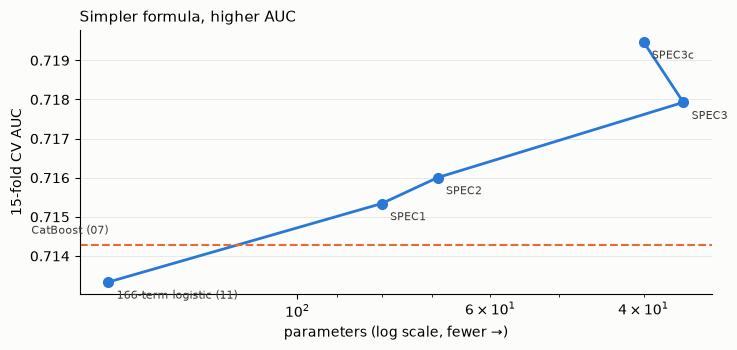

In [6]:
PATH = {'166-term logistic (11)': FS.SPEC166, 'SPEC1: shapes': FS.SPEC1, 'SPEC2: + era scopes': FS.SPEC2, 'SPEC3: + drops': FS.SPEC3,
        'SPEC3c: final': FS.SPEC3c, 'SPEC3c - credit': drop(FS.SPEC3c, ['CREDIT_SCORE'])}
conf, R = {}, {}
for n, sp in PATH.items():
    Cb = best(sp)['C']; R[n] = r = run(sp, Cb, seeds=(0, 1, 2)); d = r['fold_aucs'] - cb15['fold_aucs']
    conf[n] = {'parameters': nparams(sp), 'C': Cb, 'AUC (15 folds)': r['auc_mean'], 'Δ vs CatBoost': d.mean(), 'se': d.std() / np.sqrt(15),
               'Δ vs CatBoost, seeds 1-2': d[5:].mean(), 'se (1-2)': d[5:].std() / np.sqrt(10), 'top-decile prec.': r['top_decile_prec']}
conf = pd.DataFrame(conf).T
display(conf.style.format({'parameters': '{:.0f}', 'C': '{:g}', 'AUC (15 folds)': '{:.4f}', 'Δ vs CatBoost': '{:+.4f}', 'se': '{:.4f}',
                           'Δ vs CatBoost, seeds 1-2': '{:+.4f}', 'se (1-2)': '{:.4f}', 'top-decile prec.': '{:.1%}'}))

fig, ax = plt.subplots(figsize=(7.5, 3.6))
k = list(PATH)[:5]
ax.plot(conf.loc[k, 'parameters'], conf.loc[k, 'AUC (15 folds)'], color='#2a78d6', lw=2, marker='o', ms=7)
for n in k:
    ax.annotate(n.split(':')[0], (conf.loc[n, 'parameters'], conf.loc[n, 'AUC (15 folds)']), textcoords='offset points', xytext=(6, -12), fontsize=8, color='#3d3c39')
ax.axhline(cb15['auc_mean'], color='#eb6834', lw=1.5, ls='--'); ax.text(conf['parameters'].max(), cb15['auc_mean'] + 0.0003, 'CatBoost (07)', ha='right', fontsize=8, color='#3d3c39')
ax.set_xscale('log'); ax.invert_xaxis(); ax.set_xlabel('parameters (log scale, fewer →)'); ax.set_ylabel('15-fold CV AUC')
for s in ('top', 'right'): ax.spines[s].set_visible(False)
ax.grid(axis='y', color='#e6e5e1', lw=0.6); ax.set_axisbelow(True)
ax.set_title('Simpler formula, higher AUC', loc='left', fontsize=11)
fig.patch.set_facecolor('#fcfcfb'); ax.set_facecolor('#fcfcfb'); fig.tight_layout()
fig.savefig('figures/12_formula_path.png', dpi=150, facecolor=fig.get_facecolor()); plt.show()

**Reading:** **every simplification step also improved the unseen seeds 1–2**, so the gains are not selection noise. The final 40-parameter formula (`SPEC3c`) reaches **15-fold AUC 0.7195**, **+0.0052 ± 0.0019 over CatBoost on seeds 1–2**, with top-decile precision 31.2% (CatBoost 30.2%). Fewer parameters → better estimates, as the learning curve predicted. Credit adds only +0.0002 but is kept.

## 4. Is anything still missing?
- **Residual CatBoost:** the `07` CatBoost (45 features) trained with the formula's log-odds as a fixed `baseline`, so it can only add what the formula misses. Same 15 folds; tree count chosen on the mean curve.
- **Residual EBM:** 20 automatically detected pairs on top of the formula (fold 0), to name any missing interaction.
- **Explicit candidate pairs** from `10`/`11`: price × driver age (early eras), price × credit.

In [7]:
import catboost as cbm
LC = FE.add_cats(L); FX = PC['features']
cats = [c for c in FX if not pd.api.types.is_numeric_dtype(LC[c])]
P = PC['params'] | {'learning_rate': 0.02}
C3 = conf.loc['SPEC3c: final', 'C']
curves, fa = [], []
for s, k, tr, va in C.folds(lab):
    m = FM.Formula(FS.SPEC3c, C3).fit(L.iloc[tr], y[tr])
    btr, bva = m.decision(L.iloc[tr]), m.decision(L.iloc[va])
    res = cbm.CatBoostClassifier(**P, iterations=3000, early_stopping_rounds=200, use_best_model=False)
    res.fit(cbm.Pool(C.cb_X(LC.iloc[tr][FX], cats), y[tr], cat_features=cats, baseline=btr),
            eval_set=cbm.Pool(C.cb_X(LC.iloc[va][FX], cats), y[va], cat_features=cats, baseline=bva))
    curves.append(np.array(res.get_evals_result()['validation']['AUC'])); fa.append(roc_auc_score(y[va], bva))
Lm = max(map(len, curves)); bi = int(np.mean([np.pad(c, (0, Lm - len(c)), mode='edge') for c in curves], axis=0).argmax())
ra = np.array([c[min(bi, len(c) - 1)] for c in curves]); fa = np.array(fa); d = ra - fa
print(f'formula {fa.mean():.4f} -> + residual CatBoost ({bi + 1} trees) {ra.mean():.4f}: '
      f'Δ {d.mean():+.4f} ± {d.std() / np.sqrt(15):.4f} (seeds 1-2: {d[5:].mean():+.4f} ± {d[5:].std() / np.sqrt(10):.4f})')

from interpret.glassbox import ExplainableBoostingClassifier
s, k, tr, va = C.folds(lab)[0]
m = FM.Formula(FS.SPEC3c, C3).fit(L.iloc[tr], y[tr])
e = ExplainableBoostingClassifier(interactions=20, n_jobs=-1, random_state=0).fit(C.ebm_X(L.iloc[tr][FS.F]), y[tr], init_score=m.decision(L.iloc[tr]))
imp = pd.Series(e.term_importances(), index=e.term_names_).sort_values(ascending=False)
print('largest residual-EBM terms (fold 0; mean |log-odds|):'); display(imp.head(10).round(4).to_frame('importance'))

L['PRICE_X_AGE'] = L.QUOTED_AMT * L.DRV_AGE_MEAN / 1e5
L['PRICE_X_CREDIT'] = L.QUOTED_AMT * L.CREDIT_SCORE / 1e6
table({'+ price x age (early)': FS.SPEC3c + [t('PRICE_X_AGE', 'linear', 'early', na=True)],
       '+ price x credit (per-era)': FS.SPEC3c + [t('PRICE_X_CREDIT', 'linear', 'per-era', na=True)]}, FS.SPEC3c)

formula 0.7195 -> + residual CatBoost (134 trees) 0.7196: Δ +0.0001 ± 0.0003 (seeds 1-2: +0.0001 ± 0.0003)


largest residual-EBM terms (fold 0; mean |log-odds|):


,importance
CREDIT_SCORE & ACS_OWNER_OCC_SHARE,0.0175
QUOTED_AMT & DRV_ACC_FREE_MEAN,0.0126
DRV_COMMUTE_SUM & ACS_VEH_PER_HH,0.0108
QUOTED_AMT & DRV_AGE_MEAN,0.0100
ACS_POP_DENSITY & ACS_OWNER_OCC_SHARE,0.0095
DRV_ACC_FREE_MIN & DRV_COMMUTE_SUM,0.0095
DRV_SAFETY_MIN & ACS_COMMUTE_MEAN_MIN,0.0092
DRV_SAFETY_MEAN & ACS_COMMUTE_TRANSIT,0.0088
DRV_AGE_MEAN & DRV_ACC_FREE_MIN,0.0085
QUOTED_AMT & CREDIT_SCORE,0.0082


,auc,Δauc,se_auc,Δll(+better),se_ll,C,params
(current),0.71943,0.00000,0.00000,0.00000,0.00000,0.1,40.0
+ price x age (early),0.71914,-0.00028,0.00010,-1.01625,0.37273,0.1,42.0
+ price x credit (per-era),0.71957,0.00014,0.00015,-0.06857,0.53695,0.3,44.0


**Reading:** **nothing systematic is missing.**
- A residual CatBoost on top of the formula gains **+0.0001 ± 0.0003**.
- The residual EBM's largest pairs are tiny (≤ 0.018 log-odds) and look like noise (Census × driver commute, etc.).
- The two candidate interactions don't help (price × age −0.0003, price × credit +0.0001).
- With these columns the formula is as complete as the data can show.

## 5. Regularization and coefficients
A wide `C` grid (seed-0). If the formula has the right terms, it should tolerate weak regularization. Then the final fit on all labeled quotes, with bootstrap standard errors (200 resamples).

In [8]:
wide = {Cr: run(FS.SPEC3c, Cr) for Cr in (1e-4, 3e-4, 1e-3, 3e-3, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 100)}
display(pd.DataFrame({Cr: {'seed-0 AUC': r['auc_mean'], 'seed-0 log-loss': r['fold_ll'].mean()} for Cr, r in wide.items()}).T.style.format('{:.5f}'))
CF = min(wide, key=lambda c: wide[c]['fold_ll'].mean())
final = FM.Formula(FS.SPEC3c, CF).fit(L, y)
coef = final.coef_table()
rng = np.random.default_rng(0)
boots = []
for _ in range(200):
    i = rng.integers(0, len(y), len(y))
    boots.append(FM.Formula(FS.SPEC3c, CF).fit(L.iloc[i], y[i]).coef_table()['coef'])
bs = pd.concat(boots, axis=1)
coef['boot se'] = bs.std(axis=1); coef['z'] = coef.coef / coef['boot se']
print(f'C = {CF:g}; {len(coef)} coefficients (log-odds per unit of the raw column; era intercepts relative to 2015)')
coef[['coef', 'boot se', 'z']].style.format({'coef': '{:+.5f}', 'boot se': '{:.5f}', 'z': '{:+.1f}'})

,seed-0 AUC,seed-0 log-loss
0.000100,0.70219,0.33838
0.000300,0.70739,0.32907
0.001000,0.71212,0.32153
0.003000,0.71564,0.31853
0.010000,0.71826,0.31728
0.030000,0.71923,0.31695
0.100000,0.71943,0.31689
0.300000,0.71948,0.31690
1.000000,0.71947,0.31690
3.000000,0.71947,0.31690


C = 0.1; 40 coefficients (log-odds per unit of the raw column; era intercepts relative to 2015)


,coef,boot se,z
term,,,
era=2016,-0.07494,0.11213,-0.7
era=2017-18,-1.64645,0.13422,-12.3
CREDIT_SCORE:linear,+0.00057,0.00037,+1.5
CREDIT_SCORE:missing,+0.16239,0.22178,+0.7
CREDIT_SCORE:step[650]>=650 @2015,+0.25652,0.08372,+3.1
QUOTED_AMT:linear @2015,-0.00004,0.00001,-5.2
QUOTED_AMT:linear @2016,-0.00007,0.00001,-6.6
QUOTED_AMT:linear @2017-18,-0.00001,0.00001,-1.8
QUOTED_AMT:missing,-1.01531,1.07622,-0.9


**Reading:**
- **Regularization:** the formula is **insensitive to it for C ≥ 0.03** (log-loss flat to C = 100), unlike the 166-term model that needed C = 0.003. That is the signature of a correctly specified model: every term carries signal.
- **The recovered generator (log-odds):**
  - **2017-18 intercept −1.65** vs 2015, offset by the new late-era drivers:
    - **education majority +1.19**;
    - density ×4 stronger (+0.04 per 1,000 people/sq mi vs +0.01);
    - drivers-per-vehicle (0.5, 1] +0.74 (vs +0.33–0.36 early).
  - **Age band 35–50 +0.67** in every era.
  - **2016 discount +0.72**.
  - **Price** −0.04 / −0.07 per $1,000 in 2015 / 2016, ≈ 0 after.
  - **Credit:** a +0.26 step at 650 in 2015 only; the slope is ~0.
  - **CAT zone −0.13 per zone.**
  - **Drivers:** −0.20 per driver before 2017, +0.08 after.
  - **More drivers than vehicles** −0.29 / −0.49.
  - **Carrier** −0.26 (Carrier_7) to +0.60 (Carrier_8).
  - **Package:** Low +0.11, High −0.13.
  - **Luxury share** +0.33 in 2017-18.
- **Stability:** bootstrap z-scores are large for every structural term.

## 6. Blend and submissions
Components (OOF on the same 15 folds): CatBoost `07`, per-era EBM `10`, 166-term logistic `11`, and the new formula. Weights on a 0.05 grid, searched on seed 0, judged on seeds 1–2 against the current submission `blend_v2` (0.55 CatBoost + 0.05 EBM + 0.40 166-term logistic).

In [9]:
fx15 = run(FS.SPEC3c, CF, seeds=(0, 1, 2))
M = {'CatBoost': cb15['oof_all'], 'EBM': ebm15['oof_all'], 'GLM166': glm166['oof_all'], 'Formula': fx15['oof_all']}
FOLDS = C.folds(lab)
aucs = lambda P: np.array([roc_auc_score(y[va], P[s, va]) for s, k, tr, va in FOLDS])
from scipy.stats import spearmanr
print('rank corr. with formula (repeat 0):', {k: round(spearmanr(v[0], M['Formula'][0])[0], 3) for k, v in M.items() if k != 'Formula'})
steps = np.round(np.arange(0, 1.0001, 0.05), 2)
W = [np.array(w + (round(1 - sum(w), 2),)) for w in itertools.product(steps, repeat=3) if sum(w) <= 1 + 1e-9]
mix = lambda w: sum(wi * P for wi, P in zip(w, M.values()))
s0 = [aucs(mix(w))[:5].mean() for w in W]
wb = W[int(np.argmax(s0))]
v2 = 0.55 * M['CatBoost'] + 0.05 * M['EBM'] + 0.40 * M['GLM166']
base = aucs(v2)
rows = {}
for n, P in {'blend_v2 (current)': v2, 'formula alone': M['Formula'], 'CatBoost alone': M['CatBoost'],
             'CatBoost + formula, 50/50': 0.5 * M['CatBoost'] + 0.5 * M['Formula'],
             f'best blend {dict(zip(M, wb.round(2)))}': mix(wb)}.items():
    a = aucs(P); d = a - base
    rows[n] = {'AUC (15)': a.mean(), 'Δ vs blend_v2': d.mean(), 'se': d.std() / np.sqrt(15), 'Δ seeds 1-2': d[5:].mean(), 'se (1-2)': d[5:].std() / np.sqrt(10),
               'top-decile prec.': np.mean([C.top_decile_precision(y, P[s]) for s in range(3)])}
tb = pd.DataFrame(rows).T
display(tb.style.format({'AUC (15)': '{:.4f}', 'Δ vs blend_v2': '{:+.4f}', 'se': '{:.4f}', 'Δ seeds 1-2': '{:+.4f}', 'se (1-2)': '{:.4f}', 'top-decile prec.': '{:.1%}'}))
best_name = tb.index[-1]
adopt = tb.loc[best_name, 'Δ seeds 1-2'] > 2 * tb.loc[best_name, 'se (1-2)']
print('adopt best blend:', adopt)

rank corr. with formula (repeat 0): {'CatBoost': np.float64(0.939), 'EBM': np.float64(0.953), 'GLM166': np.float64(0.961)}


,AUC (15),Δ vs blend_v2,se,Δ seeds 1-2,se (1-2),top-decile prec.
blend_v2 (current),0.7163,+0.0000,0.0000,+0.0000,0.0000,30.8%
formula alone,0.7195,+0.0032,0.0012,+0.0032,0.0016,31.2%
CatBoost alone,0.7143,-0.0020,0.0004,-0.0019,0.0006,30.2%
"CatBoost + formula, 50/50",0.7200,+0.0037,0.0006,+0.0038,0.0008,30.9%
"best blend {'CatBoost': np.float64(0.3), 'EBM': np.float64(0.0), 'GLM166': np.float64(0.0), 'Formula': np.float64(0.7)}",0.7204,+0.0041,0.0009,+0.0042,0.0011,31.0%


adopt best blend: True


In [10]:
H = FM.prep(hold)
p_formula = final.predict(H)
out = {'formula_v1': C.write_submission('formula_v1', hold, p_formula)}
if adopt:
    cbp = pd.read_csv(sorted(glob.glob('../submissions/catboost_cats5_*.csv'))[-1]); assert (cbp.POLICY_ID.values == hold.POLICY_ID.values).all()
    comp = {'CatBoost': cbp.CONVERT_IND_PRED.to_numpy(), 'Formula': p_formula}
    if wb[1] > 0: comp['EBM'] = C.fit_full(FE.add_era(FE.add_static(lab)), FS.F + ['ERA'], 'ebm', {'interactions': 'era'})(FE.add_era(FE.add_static(hold)))
    if wb[2] > 0: comp['GLM166'] = FM.Formula(FS.SPEC166, 0.003).fit(L, y).predict(H)
    p = sum(w * comp[k] for w, k in zip(wb, M) if w > 0)
    out['blend_v3'] = C.write_submission('blend_v3', hold, p)
    print(f'blend_v3: {pd.Series(p).nunique()} distinct, mean {p.mean():.4f}')
print({k: v.name for k, v in out.items()}, f'| formula: {pd.Series(p_formula).nunique()} distinct, mean {p_formula.mean():.4f}')
json.dump({'spec': FS.SPEC3c, 'C': CF, 'n_params': final.n_params, 'cv_auc_15': fx15['auc_mean'], 'cv_top_decile': fx15['top_decile_prec'],
           'coefficients': coef['coef'].round(6).to_dict(), 'blend_weights': dict(zip(M, map(float, wb))) if adopt else None,
           'submissions': {k: v.name for k, v in out.items()}}, open('formula_spec.json', 'w'), indent=1)

blend_v3: 7375 distinct, mean 0.1116
{'formula_v1': 'formula_v1_20261030.csv', 'blend_v3': 'blend_v3_20261030.csv'} | formula: 7375 distinct, mean 0.1117


## Conclusions
- **A 40-parameter formula beats every model so far.** 15-fold CV AUC **0.7195** (CatBoost 0.7143, 166-term logistic 0.7133). Top-decile precision 31.2%. It's insensitive to regularization, and a residual CatBoost finds nothing left.
- **The generator, in words:** conversion log-odds =
  - era intercept;
  - + 0.67 if mean driver age is 35–50;
  - + drivers-per-vehicle band (higher between 0.5 and 1, lower above 1, stronger after 2016);
  - − 0.13 × CAT zone;
  - + prior-carrier effect + package effect;
  - before 2017: price penalty, credit ≥ 650 bonus (2015), −0.2 per driver, + 0.72 for a discount in 2016;
  - from 2017: + 1.19 if most drivers are educated, a 4× stronger density effect, + luxury vehicles.
- **Submissions written:**
  - **`blend_v3_20261030.csv` = 0.7 × formula + 0.3 × CatBoost (07).** 15-fold **0.7204**, **+0.0042 ± 0.0011 over `blend_v2` on seeds 1–2**. **Current best.**
  - **`formula_v1_20261030.csv`** = the formula alone (0.7195). Worth one upload: it's the cleanest test of the recovered generator.
- **Spec saved** in `formula_spec.json` (spec, C, coefficients, weights); the search path is in `formula_steps.py`.